# Introduction

In part 1 of this assessment, you will complete several requested SQL queries in order to extract data, analyze, and provide insights from a single provided SQL database. You will also visualize the key results of 3 of these queries. There are also several 'Reflection' questions that ask you to write out a text based answer in the provided markdown cell. Following the guided question and answer section, in part 2 you will explore a second dataset on your own using SQL in order to conduct a preliminary analysis. You will be asked to produce a very short slide presentation highlighting the work you did for this second section.

## Objectives
You will be able to:
- Interpret "word problems" and translate them into SQL queries
- Decide and perform whichever type of JOIN is best for retrieving desired data
- Use GROUP BY statements to apply aggregate functions like COUNT, MAX, MIN, and SUM
- Use the HAVING clause to compare different aggregates
- Write subqueries to decompose complex queries
- Visualize data using matplotlib, seaborn, or pandas
- Choose the correct chart type based on the given data


## Part 1: Guided SQL Queries

### Your Task: Querying a Customer Database

![toy car picture](images/toycars.jpg)


### Business Understanding
Your employer sells wholesale miniature models of products such as classic cars, motorcycles, and planes. They want you to pull several reports on different segments of their past customers, in order to better understand past sales as well as determine which customers will receive promotional material. They are also interested in investigating which products have performed the best, as well as having several smaller asks.

In addition to providing the requested data from the SQL database you have also been asked to create some basic visuals to display some of the more insightful information. It is up to your discretion to choose the correct plot/chart type for the data in question. **Questions that want you to visualize the results will be explicitly marked**.

### Data Understanding
You may remember this database from a previous lab. As a refresher, here's the ERD diagram for this database:

![ERD picture](images/ERD.png)

The queries you are asked to write will become more complex over the course of the lab.



### Getting Started
For this assessment you are expected to make use of both sqlite3 and the Pandas libraries in order to write, execute, and return SQL queries as a Pandas DataFrame. Assign each returned answer as its own explicit variable.

For the visualization piece you are expected to utilize either Pandas, Seaborn, or Matplotlib to create your visuals. Make sure you are providing verbose labels and titles according to the data you are being asked to visualize. Do not worry too much about choosing a 'style' or 'context' instead focus on conveying the requested information correctly.

### Step 1: Connect to Data

In the cell below
- Import the necessary libraries
- Establish a connection to the database data.sqlite

In [2]:
# Replace None with your code
# Imports
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Create connection to database
conn = sqlite3.connect('data.sqlite')
print('Connected to customer database')

Connected to customer database


### Step 2: Limited Edition California Product
The California sales rep team is interested in running promotional material for a new limited edition model they are releasing based on the famous San Francisco Cable Cars. This product will only be available to customer stores based in California and given its high price value they want to first target promotional material to existing California customers with a high credit limit. Upon communicating with the accounting department, a credit limit of over 25,000 is considered to be high. 

Execute a SQl query that returns which customers the sales rep team wants to market to first.
*Hint*: Make sure creditLimit is numeric.

In [3]:
# Replace None with your code
query_2 = """
SELECT customerNumber, customerName, city, state, creditLimit
FROM customers
WHERE state = 'CA'
  AND CAST(creditLimit AS REAL) > 25000
ORDER BY CAST(creditLimit AS REAL) DESC;
"""
california_customers = pd.read_sql_query(query_2, conn)
display(california_customers)

,customerNumber,customerName,city,state,creditLimit
0,124,Mini Gifts Distributors Ltd.,San Rafael,CA,210500.00
1,239,Collectable Mini Designs Co.,San Diego,CA,105000.00
2,321,Corporate Gift Ideas Co.,San Francisco,CA,105000.00
3,205,Toys4GrownUps.com,Pasadena,CA,90700.00
4,161,Technics Stores Inc.,Burlingame,CA,84600.00
5,450,The Sharp Gifts Warehouse,San Jose,CA,77600.00
6,129,Mini Wheels Co.,San Francisco,CA,64600.00
7,487,Signal Collectibles Ltd.,Brisbane,CA,60300.00
8,347,"Men 'R' US Retailers, Ltd.",Los Angeles,CA,57700.00
9,475,West Coast Collectables Co.,Burbank,CA,55400.00


### Step 3: International Collectable Campaign

The international sales rep team has reached out to you to help them identify partners for a 'Collectable' marketing campaign that highlights the potential collectors value in purchasing these model kits. They want to try and promote a 'collect them all' mentality. The team had a great idea to partner with any of their international customers (non-US) who have "Collect" in their name as a tie in to the larger theme.

Execute a SQL that returns the customers in question.

In [4]:
# Replace None with your code
query_3 = """
SELECT customerNumber, customerName, country, city
FROM customers
WHERE country <> 'USA'
  AND customerName LIKE '%Collect%'
ORDER BY country, customerName;
"""
international_collectors = pd.read_sql_query(query_3, conn)
display(international_collectors)

,customerNumber,customerName,country,city
0,471,"Australian Collectables, Ltd",Australia,Glen Waverly
1,114,"Australian Collectors, Co.",Australia,Melbourne
2,382,Salzburg Collectables,Austria,Salzburg
3,260,"Royal Canadian Collectables, Ltd.",Canada,Tsawassen
4,227,Heintze Collectables,Denmark,Århus
5,353,Reims Collectables,France,Reims
6,415,"Bavarian Collectables Imports, Co.",Germany,Munich
7,409,Stuttgart Collectable Exchange,Germany,Stuttgart
8,211,"King Kong Collectables, Co.",Hong Kong,Central Hong Kong
9,189,"Clover Collections, Co.",Ireland,Dublin


## Reflection Question:

Describe the WHERE clause you used in the above query to a non-technical manager who wants to be ensured that you are properly filtering and only selecting the requested data. How is the operator and conditional expression you are using acting to accomplish this?

## Type your answer in markdown here!

Two conditions are applied together in the WHERE clause. country <> 'USA' eliminates US-based clients, and customerName LIKE '%Collect%' locates names that contain "Collect" at any point. Customers must meet both requirements in order to appear in the results, according to the AND operator.

### Step 4: USA Credit and Inventory Policy - Visual Required
The USA based product team is planning to adjust its credit policies and inventory allocation strategy based on the average credit limit of its customers. They would like to target this strategy at a state level with several goals in mind. 
1. Optimize inventory distribution:
    - States with higher average credit limits might be able to place larger orders, justifying priority in inventory allocation.
    - This could help ensure that states with more purchasing power always have products in stock.
2. Tailor credit policies:
    - Adjust credit limits for new customers based on the state average.
    - Identify states where they might be too conservative or too liberal with credit limits.
3. Target marketing and sales efforts:
    - Focus promotional campaigns on states with higher credit limits, potentially leading to larger orders.
    - Develop strategies to increase sales in states with lower average credit limits.

Execute a SQl query that returns the information required to address this ask.

In [19]:
# Replace None with your code
query_4 = """
SELECT state, COUNT(*) AS customer_count,
       ROUND(AVG(CAST(creditLimit AS REAL)), 2) AS avg_credit_limit
FROM customers
WHERE country = 'USA'
  AND state IS NOT NULL AND TRIM(state) <> ''
  AND creditLimit IS NOT NULL
GROUP BY state
ORDER BY avg_credit_limit DESC;
"""
state_credit = pd.read_sql_query(query_4, conn)
display(state_credit)

,state,customer_count,avg_credit_limit
0,NH,1,114200.00
1,NY,6,89966.67
2,PA,3,84766.67
3,CA,11,83854.55
4,NV,1,71800.00
5,MA,9,70755.56
6,CT,4,57350.00
7,NJ,1,43000.00


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

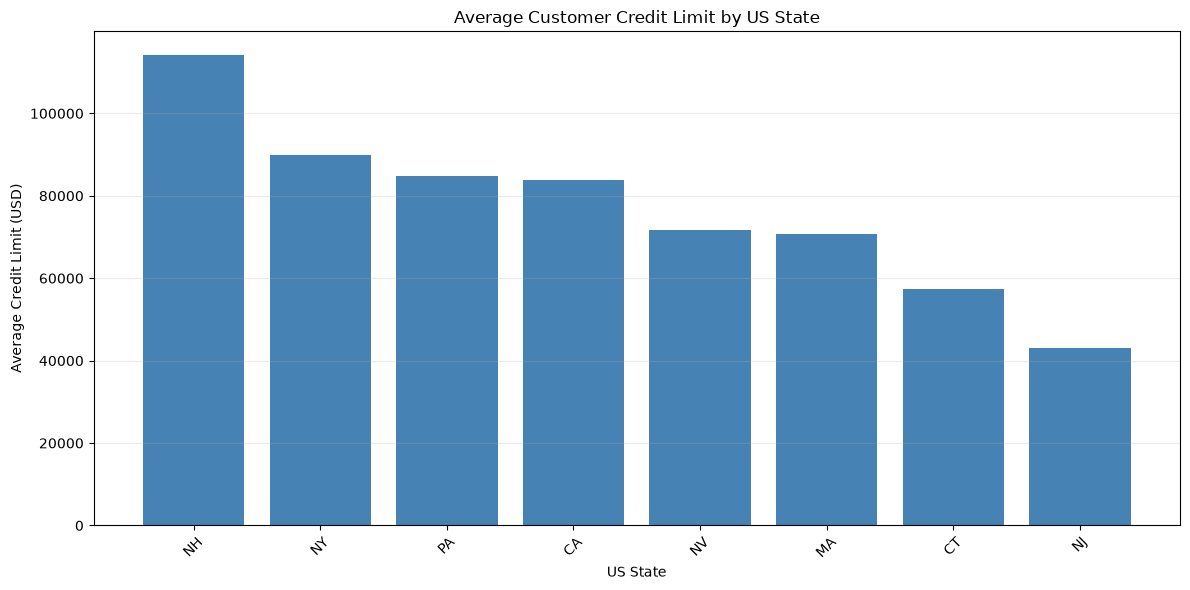

In [22]:
# Replace None with your visual code
# Produce a visual to represent the average credit limit by state
fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(state_credit['state'], state_credit['avg_credit_limit'], color='steelblue')
ax.set(title='Average Customer Credit Limit by US State', xlabel='US State', ylabel='Average Credit Limit (USD)')
ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=.25)
fig.tight_layout()
plt.show()

### Step 5: Top Customers - Visual Required
The company is approaching its 10 year anniversary and wants to acknowledge and thank its top customers with personalized communication. They have asked you to determine the top 10 customers based on the total amount of payments made, making sure to return the customer name for clarity. 

Execute a SQl query that returns the information required to address this ask.


In [21]:
# Replace None with your code
query_5 = """
SELECT c.customerNumber, c.customerName,
       ROUND(SUM(CAST(p.amount AS REAL)), 2) AS total_payments
FROM customers AS c
JOIN payments AS p ON c.customerNumber = p.customerNumber
GROUP BY c.customerNumber, c.customerName
ORDER BY total_payments DESC
LIMIT 10;
"""
top_customers = pd.read_sql_query(query_5, conn)
display(top_customers)

,customerNumber,customerName,total_payments
0,141,Euro+ Shopping Channel,715738.98
1,124,Mini Gifts Distributors Ltd.,584188.24
2,114,"Australian Collectors, Co.",180585.07
3,151,Muscle Machine Inc,177913.95
4,148,"Dragon Souveniers, Ltd.",156251.03
5,323,"Down Under Souveniers, Inc",154622.08
6,187,"AV Stores, Co.",148410.09
7,276,"Anna's Decorations, Ltd",137034.22
8,321,Corporate Gift Ideas Co.,132340.78
9,146,"Saveley & Henriot, Co.",130305.35


Once you have the information returned in a dataframe, select an appropriate visualization to represent this data. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

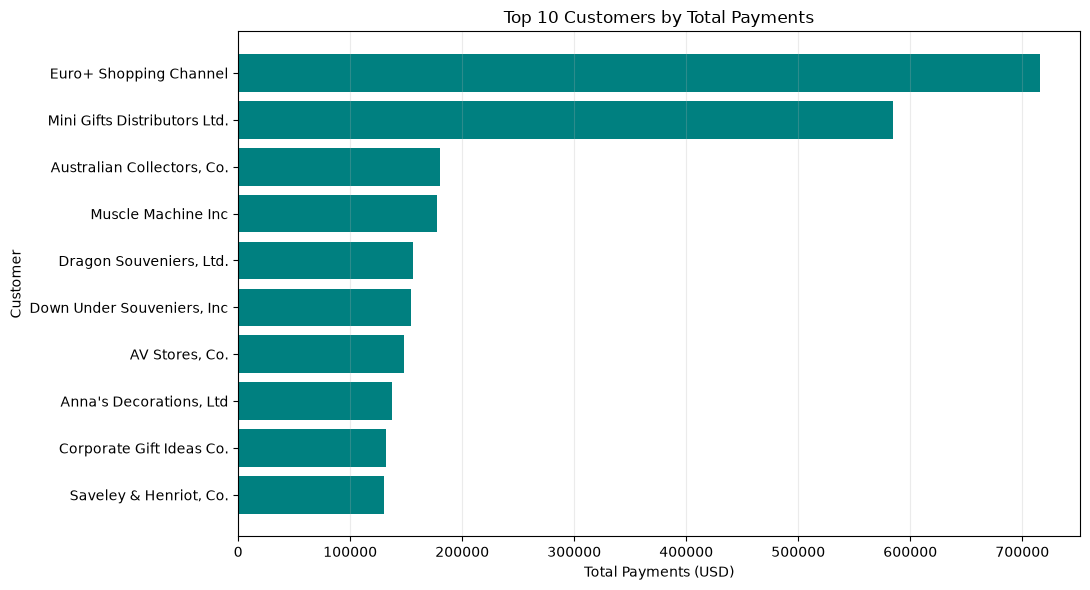

In [23]:
# Replace None with your visual code
# Produce a visual to represent the top ten customers in terms of total payments
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_customers['customerName'], top_customers['total_payments'], color='teal')
ax.invert_yaxis()
ax.set(title='Top 10 Customers by Total Payments', xlabel='Total Payments (USD)', ylabel='Customer')
ax.grid(axis='x', alpha=.25)
fig.tight_layout()
plt.show()

### Step 6: Top Customer + Product Quantities
The product team is running an analysis on popular and common products sold to each customer in order to try and determine what new products they should be looking at to include in their catalog. This data will also be used by individual sales reps to recommend similar products to each customer next time they place an order. 

They have asked you to query information, for each customer, about any product they have purchased 10 or more units of. In addition they would like the full set of data to be sorted in ascending order by the total amount purchased.

Execute a SQl query that returns the information required to address this ask.

Hint: For this one, you'll need to make use of HAVING, GROUP BY, and ORDER BY — make sure you get the order of them correct!

In [25]:
# Replace None with you code
query_6 = """
SELECT c.customerNumber, c.customerName, p.productCode, p.productName,
       SUM(CAST(od.quantityOrdered AS INTEGER)) AS total_quantity_purchased
FROM customers AS c
JOIN orders AS o ON c.customerNumber = o.customerNumber
JOIN orderdetails AS od ON o.orderNumber = od.orderNumber
JOIN products AS p ON od.productCode = p.productCode
GROUP BY c.customerNumber, c.customerName, p.productCode, p.productName
HAVING SUM(CAST(od.quantityOrdered AS INTEGER)) >= 10
ORDER BY total_quantity_purchased ASC, c.customerName, p.productName;
"""
customer_products = pd.read_sql_query(query_6, conn)
display(customer_products.head(20))
print('Matching customer-product combinations:', len(customer_products))

,customerNumber,customerName,productCode,productName,total_quantity_purchased
0,412,"Extreme Desk Decorations, Ltd",S24_4620,1961 Chevrolet Impala,10
1,314,Petit Auto,S18_2949,1913 Ford Model T Speedster,10
2,119,La Rochelle Gifts,S32_2509,1954 Greyhound Scenicruiser,11
3,328,Tekni Collectables Inc.,S700_1691,American Airlines: B767-300,11
4,450,The Sharp Gifts Warehouse,S24_3191,1969 Chevrolet Camaro Z28,13
5,386,L'ordine Souveniers,S18_2581,P-51-D Mustang,15
6,382,Salzburg Collectables,S24_2972,1982 Lamborghini Diablo,15
7,282,Souveniers And Things Co.,S24_3969,1936 Mercedes Benz 500k Roadster,15
8,398,"Tokyo Collectables, Ltd",S24_3969,1936 Mercedes Benz 500k Roadster,15
9,412,"Extreme Desk Decorations, Ltd",S18_3278,1969 Dodge Super Bee,16


Matching customer-product combinations: 2531


### Step 7: Product Analysis - Visual Required

The product team is looking into the demand across its different product lines. They are conducting a comprehensive review of its product portfolio and inventory management strategies. You have been asked to query data pertaining to each different product line, that contains the total quantity ordered and the total number of products for each respective product line. By examining the number of products and total quantity ordered for each product line, the company aims to:
1. Optimize product mix:
    - Identify which product lines have the most diverse offerings (high number of products)
    - Determine which lines are most popular (high total quantity ordered)
    - Compare if lines with more products necessarily lead to more orders
2. Improve inventory management:
    - Adjust stock levels based on the popularity of each product line
    - Identify potential overstocking in lines with low order quantities
    - Ensure adequate variety in high-performing product lines
3. Adjust marketing strategy:
    - Focus promotional efforts on product lines with high potential (many products but lower order quantities)
    - Capitalize on the popularity of high-performing lines in marketing campaigns
4. Advise Product development:
    - Invest in expanding product ranges for lines with high order quantities
    - Consider phasing out or revamping product lines with low numbers of products and low order quantities

Hint: Think about how you can and might have to utilize SQL DISTINCT statement

Execute a SQl query that returns the information required to address this ask.

In [26]:
# Replace None with your code
query_7 = """
SELECT p.productLine,
       COUNT(DISTINCT p.productCode) AS number_of_products,
       COALESCE(SUM(CAST(od.quantityOrdered AS INTEGER)), 0) AS total_quantity_ordered
FROM products AS p
LEFT JOIN orderdetails AS od ON p.productCode = od.productCode
GROUP BY p.productLine
ORDER BY total_quantity_ordered DESC;
"""
product_analysis = pd.read_sql_query(query_7, conn)
display(product_analysis)

,productLine,number_of_products,total_quantity_ordered
0,Classic Cars,38,35582
1,Vintage Cars,24,22933
2,Motorcycles,13,12778
3,Planes,12,11872
4,Trucks and Buses,11,11001
5,Ships,9,8532
6,Trains,3,2818


Once you have the information returned in a dataframe, select an appropriate visualization to represent the relationship between total quantity ordered and the number of products in order to perform a preliminary investigation into the question of if more products lead to more orders. You are welcome to utilize matplotlib, seaborn, or pandas plotting to produce your visual. Ensure that it has a verbose title and axis labels!

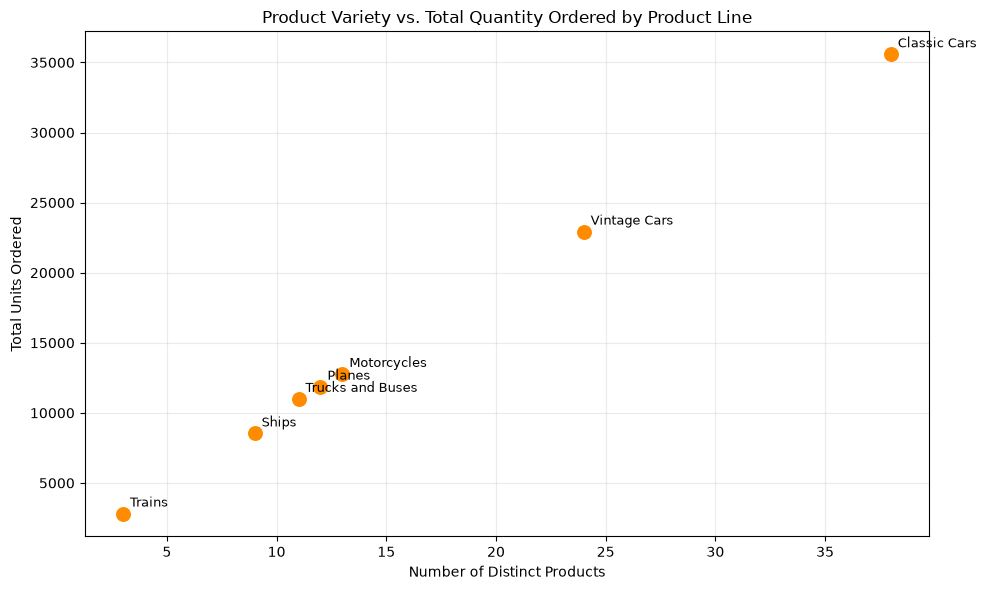

In [27]:
# Replace None with your visual code
# Produce a visual to represent the the relation between number of products and the total amount ordered
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(product_analysis['number_of_products'], product_analysis['total_quantity_ordered'], s=95, color='darkorange')
for _, item in product_analysis.iterrows():
    ax.annotate(item['productLine'], (item['number_of_products'], item['total_quantity_ordered']), xytext=(5, 5), textcoords='offset points', fontsize=9)
ax.set(title='Product Variety vs. Total Quantity Ordered by Product Line', xlabel='Number of Distinct Products', ylabel='Total Units Ordered')
ax.grid(alpha=.25)
fig.tight_layout()
plt.show()

## Reflection Question:

Please explain your choice in the type of visual you used in order to highlight and represent the data from the above query. In a non-technical manner explain why that chart type makes sense for the information being conveyed. What does this visual convey in the context of the question it was asked for?

## Type your answer in markdown here!

I chose a scatter plot because it compares two numbers for each product line: the number of different products and the total quantity ordered. A single product line is represented by each point. This facilitates determining whether product lines with greater diversity also typically have higher order volumes. It doesn't prove that adding products increases sales; rather, it demonstrates a relationship.

### Step 8: Remote Offices
Upper management is considering a shift to hybrid and remote work for certain locations and roles. They have tasked you with providing them data about employees who work in any office that has fewer than 5 total employees so they can better understand how to support those employees remotely when offices are shut down. 

Be sure to include information about the employees job and supervisor so management can adjust everyone to remote work properly.

Hint: Utilize a subquery to find the relevant offices

Execute a SQl query that returns the information required to address this ask.

In [28]:
# Replace None with your code
query_8 = """
SELECT e.employeeNumber, e.firstName, e.lastName, e.jobTitle,
       e.officeCode, o.city, o.country, e.reportsTo,
       TRIM(COALESCE(s.firstName, '') || ' ' || COALESCE(s.lastName, '')) AS supervisor_name
FROM employees AS e
JOIN offices AS o ON e.officeCode = o.officeCode
LEFT JOIN employees AS s ON e.reportsTo = s.employeeNumber
WHERE e.officeCode IN (
    SELECT officeCode
    FROM employees
    GROUP BY officeCode
    HAVING COUNT(*) < 5
)
ORDER BY o.city, e.lastName, e.firstName;
"""
remote_employees = pd.read_sql_query(query_8, conn)
display(remote_employees)

,employeeNumber,firstName,lastName,jobTitle,officeCode,city,country,reportsTo,supervisor_name
0,1188,Julie,Firrelli,Sales Rep,2,Boston,USA,1143,Anthony Bow
1,1216,Steve,Patterson,Sales Rep,2,Boston,USA,1143,Anthony Bow
2,1501,Larry,Bott,Sales Rep,7,London,UK,1102,Gerard Bondur
3,1504,Barry,Jones,Sales Rep,7,London,UK,1102,Gerard Bondur
4,1286,Foon Yue,Tseng,Sales Rep,3,NYC,USA,1143,Anthony Bow
5,1323,George,Vanauf,Sales Rep,3,NYC,USA,1143,Anthony Bow
6,1611,Andy,Fixter,Sales Rep,6,Sydney,Australia,1088,William Patterson
7,1619,Tom,King,Sales Rep,6,Sydney,Australia,1088,William Patterson
8,1612,Peter,Marsh,Sales Rep,6,Sydney,Australia,1088,William Patterson
9,1088,William,Patterson,Sales Manager (APAC),6,Sydney,Australia,1056,Mary Patterson


## Reflection Question:

Describe how you decided on the subquery that you used in the query above? This answer can be technically in nature, describing your thought process in how the main query is utilizing the subquery to return the correct data.

## Type your answer in markdown here!

I had to start by determining which offices employ fewer than five people. HAVING COUNT(*) < 5 is used in the subquery to group employees by office. Employees whose office code appears in that list are subsequently chosen by the main query. Additionally, it joins employees a second time to display each employee's supervisor and joins the offices table for location information.

### Step 9: Close the Connection

Now that you are finished executing your queries and retrieving the required information you always want to make sure to close the connection to your database.

In [29]:
# Replace None with your code
conn.close()
print('Customer database connection closed.')

Customer database connection closed.


### End of Guided Section
In this initial portion of the assessment, you produced several data queries and visualizations for a model company, mainly focused around its customer and product data. You wrote and engineered specific SQL queries to address pertinent questions and asks from the company. Along the way, you utilized many of the major concepts and keywords associated with SQL SELECT queries: FROM, WHERE, GROUP BY, HAVING, ORDER BY, JOIN, SUM, COUNT, and AVG.

## Part 2: Exploratory Analysis with SQL
In this open-ended exploratory section, you will analyze real-world data from the movie industry. As a data analyst, you have the freedom to investigate questions and topics that intrigue you within this dataset. The database schema and Entity-Relationship Diagram (ERD) are provided below for your reference. A general overview and instructions are also provided below.

In [30]:
# Run this cell without changes
import zipfile

zip_file_path = 'im.db.zip'
extract_to_path = './'

with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to_path)

# Connection
conn4 = sqlite3.connect('im.db')

# Schema
schema_df = pd.read_sql("""
SElECT * FROM sqlite_master                        
""", conn4)
schema_df

,type,name,tbl_name,rootpage,sql
0,table,movie_basics,movie_basics,2,"CREATE TABLE ""movie_basics"" (\n""movie_id"" TEXT..."
1,table,directors,directors,3,"CREATE TABLE ""directors"" (\n""movie_id"" TEXT,\n..."
2,table,known_for,known_for,4,"CREATE TABLE ""known_for"" (\n""person_id"" TEXT,\..."
3,table,movie_akas,movie_akas,5,"CREATE TABLE ""movie_akas"" (\n""movie_id"" TEXT,\..."
4,table,movie_ratings,movie_ratings,6,"CREATE TABLE ""movie_ratings"" (\n""movie_id"" TEX..."
5,table,persons,persons,7,"CREATE TABLE ""persons"" (\n""person_id"" TEXT,\n ..."
6,table,principals,principals,8,"CREATE TABLE ""principals"" (\n""movie_id"" TEXT,\..."
7,table,writers,writers,9,"CREATE TABLE ""writers"" (\n""movie_id"" TEXT,\n ..."


## The Data

![movie ERD](images/movie_data_erd.jpeg)
### Database Content:

- Source: IMDB
- Time Range: Movies released between 2010 and 2019
- Note: Exclude any movies with a start_year after 2019 as this data is not current or accurate

Available Data Categories:
- Genre
- Runtime
- Personnel (writers, directors, actors)
- Movie ratings

### Objectives:

Initial Exploration:
- Use SQL in combination with Pandas to explore the database
- Identify interesting trends, patterns, or relationships in the data

Business Question Formulation:
- Develop at least one substantial business question for deeper analysis
- Ensure the question is relevant, specific, and can be addressed with the available data

Data Cleaning Assessment:
- Identify potential data cleaning tasks necessary for your deeper analysis
- Note: You are not required to perform the cleaning, only to recognize and list the necessary tasks

Null Value Handling:
- Be aware that the dataset contains null values in certain fields
- Exclude these null values from your exploration
- Do not attempt to input or fill in missing information

### Deliverables:

You need to produce a short slide presentation (3-5 slides) that highlights the three key deliverables below. Utilize a data visualization to support the second deliverable.

1. A summary of your initial data exploration findings
    - Can be bulleted or sentence form
2. At least one well-formulated business question for further analysis
    - Should stem from a relevant trend or pattern your initial exploration identified
3. A list of potential data cleaning tasks identified during your exploration
    - This can and should include things like data normalization/standardization and null handling

Tips for Success:

Begin with broad exploratory queries to understand the data's scope and content. Then focus on honing in on interesting relationships between different data categories. Consider industry trends, audience preferences, or financial aspects when formulating your business question. Pay attention to data quality issues, inconsistencies, or limitations that might affect your analysis. Remember, the goal is to demonstrate your analytical thinking and ability to derive meaningful insights from complex datasets. Good luck with your exploration!

NOTE: You do not need to explore every aspect of this database. Find something that you think is interesting or relevant about the data and focus your exploration there.

# Review table names and basic row counts.

In [31]:
# Begin your code here
# List all database tables 
tables = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conn4)
display(tables)

,name
0,directors
1,known_for
2,movie_akas
3,movie_basics
4,movie_ratings
5,persons
6,principals
7,writers


In [32]:
# Count movies, distinct IDs, and missing genre fields in the target years.
movie_overview = pd.read_sql_query("""
SELECT COUNT(*) AS movie_records,
       COUNT(DISTINCT movie_id) AS unique_movie_ids,
       SUM(CASE WHEN genres IS NULL OR TRIM(genres) = '' THEN 1 ELSE 0 END) AS missing_genres,
       SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS missing_runtime
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)
display(movie_overview)

,movie_records,unique_movie_ids,missing_genres,missing_runtime
0,145081,145081,5359,30765


In [33]:
# Summarize ratings and votes for movies with a matching rating record.
rating_overview = pd.read_sql_query("""
SELECT COUNT(*) AS rated_movies,
       ROUND(AVG(r.averagerating), 2) AS overall_avg_rating,
       SUM(CASE WHEN r.numvotes IS NULL THEN 1 ELSE 0 END) AS missing_votes
FROM movie_basics AS b
JOIN movie_ratings AS r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND r.averagerating IS NOT NULL;
""", conn4)
display(rating_overview)

,rated_movies,overall_avg_rating,missing_votes
0,73856,6.33,0


# Movie Genre Exploration

Exploratory Question: Which genres have the greatest average IMDb ratings, and to what extent are those averages supported by audience voting? Divide the comma-separated genre field before grouping because films can have more than one genre. Limit the years to 2010–2019, exclude missing categories and ratings, and maintain a minimum of 20 rated films per genre for the chart.

In [35]:
query_movie_genres = """
SELECT b.movie_id, b.primary_title, b.start_year, b.genres,
       b.runtime_minutes, r.averagerating, r.numvotes
FROM movie_basics AS b
JOIN movie_ratings AS r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019
  AND b.genres IS NOT NULL AND TRIM(b.genres) <> ''
  AND r.averagerating IS NOT NULL
  AND r.numvotes IS NOT NULL;
  """

In [36]:
# Run the SQL query and save the results as a Pandas DataFrame.
movies_df = pd.read_sql_query(query_movie_genres, conn4)
print('Movies with usable genre and rating information:', len(movies_df))
display(movies_df.head())

Movies with usable genre and rating information: 73052


,movie_id,primary_title,start_year,genres,runtime_minutes,averagerating,numvotes
0,tt0063540,Sunghursh,2013,"Action,Crime,Drama",175.0,7.0,77
1,tt0066787,One Day Before the Rainy Season,2019,"Biography,Drama",114.0,7.2,43
2,tt0069049,The Other Side of the Wind,2018,Drama,122.0,6.9,4517
3,tt0069204,Sabse Bada Sukh,2018,"Comedy,Drama",NaN,6.1,13
4,tt0100275,The Wandering Soap Opera,2017,"Comedy,Drama,Fantasy",80.0,6.5,119


Split comma-separated genres and give each genre its own row.
A movie tagged with two genres appears once in each genre group.

In [37]:
movie_genres = movies_df.assign(genre=movies_df['genres'].str.split(',')).explode('genre')

In [38]:
# Remove extra spaces around genre names before grouping.
movie_genres['genre'] = movie_genres['genre'].str.strip()
movie_genres = movie_genres[movie_genres['genre'].ne('')]

In [39]:
# Calculate the number of distinct movies, average rating, and median votes per genre.
genre_summary = (movie_genres.groupby('genre', as_index=False)
    .agg(movie_count=('movie_id', 'nunique'),
         average_rating=('averagerating', 'mean'),
         median_votes=('numvotes', 'median')))

In [40]:
# Round averages for readability, then sort from highest to lowest rating.
genre_summary['average_rating'] = genre_summary['average_rating'].round(2)

In [41]:
# Display Results.
genre_summary = genre_summary.sort_values(['average_rating', 'movie_count'], ascending=[False, False])
display(genre_summary)

,genre,movie_count,average_rating,median_votes
21,Short,1,8.80,8.0
7,Documentary,17753,7.33,19.0
11,Game-Show,2,7.30,1734.5
17,News,579,7.27,19.0
4,Biography,3809,7.16,40.0
14,Music,1968,7.09,42.0
12,History,2825,7.04,38.0
22,Sport,1179,6.96,66.0
24,War,853,6.58,82.0
15,Musical,721,6.50,39.0


# Visualization

Keep genres with at least 20 rated movies to avoid tiny sample sizes.
Select the 10 genres with the highest mean ratings.
Sort the chart data so the highest-rated genre appears at the top.

In [42]:
eligible_genres = genre_summary[genre_summary['movie_count'] >= 20].copy()
top_genres = eligible_genres.nlargest(10, 'average_rating').sort_values('average_rating')

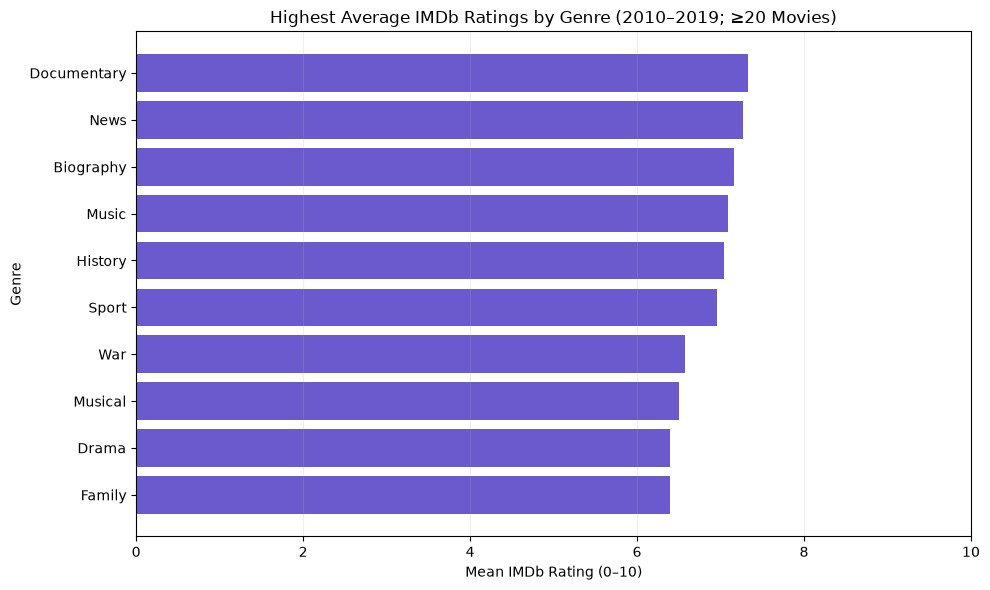

In [43]:
# Horizontal bar chart to compare the average ratings clearly.
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_genres['genre'], top_genres['average_rating'], color='slateblue')
ax.set(title='Highest Average IMDb Ratings by Genre (2010–2019; ≥20 Movies)',
       xlabel='Mean IMDb Rating (0–10)', ylabel='Genre', xlim=(0, 10))
ax.grid(axis='x', alpha=.2)
fig.tight_layout()
plt.show()

In [44]:
# Print two useful observations 
print('Highest-rated eligible genre:', eligible_genres.iloc[0]['genre'])
print('Most represented genre:', genre_summary.loc[genre_summary['movie_count'].idxmax(), 'genre'])
print('Note: A genre average is not the same as a vote-weighted audience score.')

Highest-rated eligible genre: Documentary
Most represented genre: Drama
Note: A genre average is not the same as a vote-weighted audience score.


# Business Question and Interpretation

Business Question: Which genres have the highest average IMDb ratings among those with at least 20 rated films released between 2010 and 2019, and how do their movie counts and voting levels compare?

Why it matters: This initial pattern can be used by producers and distributors to determine which genres require additional market study. Profitability cannot be determined only by ratings, as films from various genres are included in many groups.

Interpretation: Determine the most popular genre and compare it with the genre with the most films by using the printed results and chart above. Refrain from asserting that box office results are guaranteed by ratings or that genre leads to better ratings.

# Data Quality Assessment

 Count missing or inconsistent values to identify possible cleaning tasks.
Assess cleaning needs, not changing or filling the data.

In [45]:
quality_checks = pd.read_sql_query("""
SELECT COUNT(*) AS movie_rows_2010_2019,
       COUNT(DISTINCT movie_id) AS distinct_movie_ids,
       SUM(CASE WHEN genres IS NULL OR TRIM(genres) = '' THEN 1 ELSE 0 END) AS missing_genre_rows,
       SUM(CASE WHEN runtime_minutes IS NULL THEN 1 ELSE 0 END) AS missing_runtime_rows,
       SUM(CASE WHEN primary_title IS NULL OR TRIM(primary_title) = '' THEN 1 ELSE 0 END) AS missing_title_rows
FROM movie_basics
WHERE start_year BETWEEN 2010 AND 2019;
""", conn4)
display(quality_checks)

,movie_rows_2010_2019,distinct_movie_ids,missing_genre_rows,missing_runtime_rows,missing_title_rows
0,145081,145081,5359,30765,0


In [46]:
# Use a LEFT JOIN to count movies with no matching record in movie_ratings.
ratings_missing = pd.read_sql_query("""
SELECT COUNT(*) AS movies_without_rating
FROM movie_basics AS b
LEFT JOIN movie_ratings AS r ON b.movie_id = r.movie_id
WHERE b.start_year BETWEEN 2010 AND 2019 AND r.movie_id IS NULL;
""", conn4)
display(ratings_missing)

,movies_without_rating
0,71225


# Potential data cleaning tasks
1. Missing values: This analysis should not include null genre or rating data; missing runtime should be evaluated independently. Don't make up or fill in the blanks.
2. Multi-label genres: Divide genres into comma-separated categories so that films are included in each category; note any overlaps in category totals.
3. Duplicates: After joins, look for accidental duplicates and duplicated movie_id values.
4. Standardisation: Verify numeric fields, date/year forms, genre labels, and whitespace.
5. Coverage and bias: To prevent low-engagement films from dominating interpretation, keep films from 2010 to 2019 and check vote totals.

# Close Connection

In [47]:
# Close the IMDb database connection 
conn4.close()
print('Movie database connection closed.')

Movie database connection closed.
